# Regime Structure 01 — do Ivan's regimes exist as persistent states beyond volatility? (15 min – 4 h)

Pre-registration: `discussions/Regime_Structure/001_claude_branch_preregistration.md`. Definitions, null, windows and gates are fixed in
`src/data_engineering/modeling/regime_structure.py` (`registration()` below). No VWAP anywhere.

- **Data:** Binance USD-M perpetual 1m klines for BTC, ETH, SOL, XRP → 5m bars → clock-aligned windows of 15 min, 30 min, **1 h (primary)**, 2 h, 4 h ($n=3,6,12,24,48$ bars).
- **Hourly quantities:** $ER=\lvert\sum r\rvert/\sum\lvert r\rvert$, $s=\hat\sigma_{\text{pre}}\sqrt{12}$, shock $=\max\lvert r_5\rvert/\hat\sigma_{\text{pre}}$, time-of-day-relative volume and realised vol, window CVD change.
- **Labels (first match wins):** SHOCK ($\ge 3\hat\sigma$) → DISP (high $ER$, $\lvert\text{net}\rvert\ge s$, CVD agrees) → NOISE (low relative volume and vol) → RANGE (low $ER$, $\lvert\text{net}\rvert<s$) → OTHER. Thresholds = development-window quantiles, frozen.
- **Null (v1.1):** each 1m return and its taker delta multiplied by a random sign, the same sign for every asset in the same UTC minute — volatility, volume and time of day kept exactly, all directional structure destroyed.
- **Tests (test window from 2026-04-01, pooled):** lift $=P(Y_{h+1}\mid X_h)/P(Y_{h+1})$ for E1 RANGE→RANGE, E2 DISP→DISP, C1 RANGE→DISP, C2 DISP→NOISE, C3 up-DISP→SHOCK. Lifts pooled as the geometric mean over assets. Pass: lift / null median $\ge 1.10$ and permutation $p\le 0.05/5$ for the primary 1 h family, $p\le 0.05/20$ for the sweep family (15 min, 30 min, 2 h, 4 h). 399 null draws.

Environment: `RS01_ASSETS` (default BTC,ETH,SOL,XRP), `RS01_N_NULL` (default 399), `BINANCE_UM_DIR`, `RS01_SYNTHETIC=1` (synthetic smoke run, outputs to a temp dir).

In [8]:
from pathlib import Path
import json, os, sys, tempfile, time, warnings
from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 250)
load_dotenv()
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
import importlib
from data_engineering.modeling import regime_structure as rs
rs = importlib.reload(rs)   # a kernel that imported an older version keeps it otherwise

SYNTHETIC = os.getenv('RS01_SYNTHETIC', '').strip() == '1'
ASSETS = [a.strip().upper() for a in os.getenv('RS01_ASSETS', ','.join(rs.ASSETS)).split(',') if a.strip()]
P = replace(rs.Params(), n_null=int(os.getenv('RS01_N_NULL', str(rs.Params().n_null))))
if SYNTHETIC:
    BIN_DIR = None
    OUT = Path(tempfile.mkdtemp(prefix='rs01_'))
else:
    BIN_DIR = Path(os.getenv('BINANCE_UM_DIR') or Path(os.environ['DERIBIT_DATA_ROOT']).parent / 'Binance').expanduser().resolve()
    OUT = PROJECT_ROOT / 'notebooks' / 'Regime_Structure' / '01'
OUT.mkdir(parents=True, exist_ok=True)
REG = rs.registration(P)
assert rs.VERSION.startswith('regime_structure v1.2'), f'old module loaded: {rs.VERSION} - restart the kernel'
print('Regime Structure 01 |', rs.VERSION, '| synthetic' if SYNTHETIC else f'| data {BIN_DIR}', '| out', OUT)
print(json.dumps({k: REG[k] for k in ('scales', 'shock_k', 'move_k', 'er_lo_q', 'er_hi_q', 'rvol_q', 'rrv_q', 'n_null',
                                       'alpha_per_test', 'alpha_sweep', 'min_effect', 'test_start')}, default=str))
SC = list(P.scales); N0 = P.n_bars
MIN = {n: f'{n * P.bar_min}m' if n * P.bar_min < 60 else f'{n * P.bar_min // 60}h' for n in SC}

Regime Structure 01 | regime_structure v1.2 | data D:\MarketData\Binance | out D:\Projects\deribit_market_data\notebooks\Regime_Structure\01
{"scales": [3, 6, 12, 24, 48], "shock_k": 3.0, "move_k": 1.0, "er_lo_q": 0.33, "er_hi_q": 0.67, "rvol_q": 0.25, "rrv_q": 0.33, "n_null": 399, "alpha_per_test": 0.01, "alpha_sweep": 0.0025, "min_effect": 1.1, "test_start": "2026-04-01 00:00:00+00:00"}


## 1. Labels on real data and on the sign-randomised null

In [9]:
RES = {}
for i, a in enumerate(ASSETS):
    t0 = time.time()
    if SYNTHETIC:
        df = rs.synthetic_klines(n_days=200, seed=20 + i, regime=(i % 2 == 0))
    else:
        path = BIN_DIR / f'{a}USDT_um_1m.parquet'
        if not path.exists():
            print(f'{a}: no Binance file at {path} -> skipped'); continue
        df = pd.read_parquet(path, columns=['open_time', 'close', 'volume', 'taker_buy_volume'])
    RES[a] = rs.run_asset(df, P)
    print(f'{a}: {RES[a]["minutes"]:,} minutes ({RES[a]["missing_minutes"]} missing), {len(RES[a]["labels"]):,} hours, '
          f'{P.n_null} null draws x {len(SC)} scales, {time.time() - t0:.0f}s')

base = pd.concat({(MIN[n], a): r['labels'][n].groupby('window')['label'].value_counts(normalize=True).unstack()
                  for n in SC for a, r in RES.items()}, names=['scale', 'asset']).reindex(columns=rs.LABELS).round(3)
print('Label base rates (share of windows):'); display(base)
thr = pd.DataFrame({(MIN[n], a): {k: v for k, v in r['thresholds'][n].items() if not isinstance(v, list)}
                    for n in SC for a, r in RES.items()}).T
print('Frozen thresholds (development window):'); display(thr.round(4))

BTC: 1,066,980 minutes (0 missing), 5 hours, 399 null draws x 5 scales, 142s
ETH: 1,066,980 minutes (0 missing), 5 hours, 399 null draws x 5 scales, 151s
SOL: 1,066,980 minutes (0 missing), 5 hours, 399 null draws x 5 scales, 135s
XRP: 1,066,980 minutes (0 missing), 5 hours, 399 null draws x 5 scales, 126s
Label base rates (share of windows):


label               SHOCK   DISP  NOISE  RANGE  OTHER
scale asset window                                   
15m   BTC   dev     0.042  0.147  0.172  0.257  0.382
            test    0.049  0.132  0.252  0.231  0.336
      ETH   dev     0.044  0.143  0.167  0.258  0.388
            test    0.049  0.119  0.304  0.211  0.317
      SOL   dev     0.037  0.157  0.153  0.264  0.390
            test    0.044  0.133  0.285  0.226  0.312
      XRP   dev     0.038  0.146  0.172  0.256  0.388
            test    0.042  0.128  0.343  0.206  0.281
30m   BTC   dev     0.079  0.151  0.179  0.241  0.350
            test    0.092  0.137  0.266  0.210  0.295
      ETH   dev     0.083  0.147  0.177  0.244  0.349
            test    0.093  0.125  0.315  0.190  0.276
      SOL   dev     0.071  0.168  0.160  0.250  0.351
            test    0.084  0.136  0.293  0.204  0.283
      XRP   dev     0.073  0.149  0.181  0.240  0.357
            test    0.080  0.135  0.359  0.179  0.247
1h    BTC   dev     0.145  0.136  0.183  0.218  0.317
            test    0.168  0.127  0.265  0.181  0.258
      ETH   dev     0.154  0.130  0.177  0.220  0.320
            test    0.173  0.101  0.313  0.166  0.246
      SOL   dev     0.132  0.157  0.162  0.229  0.320
            test    0.158  0.125  0.292  0.176  0.249
      XRP   dev     0.135  0.133  0.186  0.221  0.325
            test    0.156  0.116  0.362  0.152  0.214
2h    BTC   dev     0.254  0.103  0.176  0.183  0.285
            test    0.287  0.092  0.254  0.154  0.213
      ETH   dev     0.269  0.100  0.172  0.187  0.271
            test    0.295  0.077  0.295  0.144  0.189
      SOL   dev     0.233  0.123  0.159  0.204  0.282
            test    0.269  0.101  0.273  0.148  0.209
      XRP   dev     0.243  0.103  0.179  0.191  0.285
            test    0.263  0.098  0.342  0.123  0.174
4h    BTC   dev     0.413  0.062  0.152  0.141  0.231
            test    0.455  0.054  0.224  0.114  0.153
      ETH   dev     0.428  0.068  0.148  0.145  0.212
            test    0.463  0.046  0.237  0.107  0.147
      SOL   dev     0.387  0.082  0.136  0.161  0.235
            test    0.432  0.059  0.236  0.121  0.151
      XRP   dev     0.401  0.062  0.157  0.145  0.235
            test    0.418  0.069  0.282  0.099  0.132

Frozen thresholds (development window):


er_lo   er_hi  rvol_q   rrv_q
15m BTC  0.3859  0.8460  0.5841  0.7345
    ETH  0.3851  0.8289  0.5833  0.7431
    SOL  0.3865  0.8438  0.6330  0.7589
    XRP  0.3887  0.8459  0.5952  0.7346
30m BTC  0.2417  0.5155  0.6000  0.7685
    ETH  0.2348  0.5098  0.5998  0.7775
    SOL  0.2415  0.5200  0.6465  0.7981
    XRP  0.2346  0.5136  0.6158  0.7668
1h  BTC  0.1596  0.3480  0.6170  0.7916
    ETH  0.1561  0.3467  0.6141  0.8007
    SOL  0.1605  0.3580  0.6666  0.8214
    XRP  0.1608  0.3496  0.6342  0.7875
2h  BTC  0.1092  0.2409  0.6247  0.8015
    ETH  0.1080  0.2410  0.6344  0.8172
    SOL  0.1104  0.2429  0.6698  0.8355
    XRP  0.1048  0.2391  0.6452  0.7971
4h  BTC  0.0752  0.1680  0.6464  0.8101
    ETH  0.0745  0.1708  0.6333  0.8240
    SOL  0.0793  0.1725  0.6828  0.8401
    XRP  0.0762  0.1718  0.6625  0.7943

## 2. Decisions — pooled over assets, test window (primary 1 h; sweep 15 min / 30 min / 2 h / 4 h)

In [10]:
EVAL = []
for n in SC:
    ev = rs.evaluate([r['counts'][n] for r in RES.values()], [r['null_counts'][n] for r in RES.values()], P,
                     alpha=P.alpha if n == N0 else P.alpha_sweep)
    ev.insert(0, 'scale', MIN[n]); ev.insert(1, 'family', 'primary' if n == N0 else 'sweep')
    EVAL.append(ev)
allres = pd.concat(EVAL, ignore_index=True)
cols = ['scale', 'family', 'window', 'test', 'from', 'to', 'n_from', 'share_from_real', 'share_from_null',
        'p_to_given_from', 'p_to', 'lift_real', 'lift_null_median', 'lift_null_q95', 'ratio_to_null', 'p_value', 'alpha', 'pass']
display(allres[cols].round(4))
decision = allres[allres['window'] == 'test'][['scale', 'family', 'test', 'from', 'to', 'lift_real', 'ratio_to_null',
                                              'p_value', 'alpha', 'pass']]
print('DECISION (test window):'); display(decision.round(4))
print('Ratio to null by scale (test window):')
display(decision.pivot_table(index='test', columns='scale', values='ratio_to_null', sort=False)[[MIN[n] for n in SC]].round(3))

,scale,family,window,test,from,to,n_from,share_from_real,share_from_null,p_to_given_from,p_to,lift_real,lift_null_median,lift_null_q95,ratio_to_null,p_value,alpha,pass
0,15m,sweep,dev,C1,RANGE,DISP,54301,0.2587,0.2690,0.1508,0.1482,1.0174,0.9975,1.0130,1.0200,0.0250,0.0025,False
1,15m,sweep,dev,C2,DISP,NOISE,31110,0.1482,0.1565,0.1267,0.1660,0.7644,0.9480,0.9703,0.8064,1.0000,0.0025,False
2,15m,sweep,dev,C3,upDISP,SHOCK,15059,0.0717,0.0782,0.0533,0.0402,1.3283,1.1115,1.1851,1.1951,0.0025,0.0025,True
3,15m,sweep,dev,E1,RANGE,RANGE,54301,0.2587,0.2690,0.2748,0.2587,1.0620,1.0859,1.0986,0.9780,1.0000,0.0025,False
4,15m,sweep,dev,E2,DISP,DISP,31110,0.1482,0.1565,0.1507,0.1482,1.0175,1.0456,1.0659,0.9731,0.9825,0.0025,False
5,15m,sweep,test,C1,RANGE,DISP,16282,0.2186,0.2202,0.1272,0.1280,0.9942,1.0062,1.0365,0.9881,0.7200,0.0025,False
6,15m,sweep,test,C2,DISP,NOISE,9534,0.1280,0.1491,0.2097,0.2960,0.7027,0.9393,0.9685,0.7481,1.0000,0.0025,False
7,15m,sweep,test,C3,upDISP,SHOCK,4601,0.0618,0.0745,0.0669,0.0457,1.4717,1.1212,1.2637,1.3126,0.0025,0.0025,True
8,15m,sweep,test,E1,RANGE,RANGE,16282,0.2186,0.2202,0.2624,0.2186,1.1998,1.2001,1.2248,0.9998,0.5075,0.0025,False
9,15m,sweep,test,E2,DISP,DISP,9534,0.1280,0.1491,0.1371,0.1280,1.0712,1.0503,1.0881,1.0199,0.1875,0.0025,False


DECISION (test window):


,scale,family,test,from,to,lift_real,ratio_to_null,p_value,alpha,pass
5,15m,sweep,C1,RANGE,DISP,0.9942,0.9881,0.7200,0.0025,False
6,15m,sweep,C2,DISP,NOISE,0.7027,0.7481,1.0000,0.0025,False
7,15m,sweep,C3,upDISP,SHOCK,1.4717,1.3126,0.0025,0.0025,True
8,15m,sweep,E1,RANGE,RANGE,1.1998,0.9998,0.5075,0.0025,False
9,15m,sweep,E2,DISP,DISP,1.0712,1.0199,0.1875,0.0025,False
15,30m,sweep,C1,RANGE,DISP,0.9658,0.9749,0.8300,0.0025,False
16,30m,sweep,C2,DISP,NOISE,0.7265,0.7416,1.0000,0.0025,False
17,30m,sweep,C3,upDISP,SHOCK,1.2240,1.1390,0.0325,0.0025,False
18,30m,sweep,E1,RANGE,RANGE,1.3194,1.0548,0.0075,0.0025,False
19,30m,sweep,E2,DISP,DISP,1.0469,1.0154,0.3100,0.0025,False


Ratio to null by scale (test window):


scale,15m,30m,1h,2h,4h
test,,,,,
C1,0.988,0.975,0.907,0.923,0.865
C2,0.748,0.742,0.702,0.636,0.680
C3,1.313,1.139,1.187,1.139,1.150
E1,1.000,1.055,1.018,1.066,1.235
E2,1.020,1.015,1.004,1.010,1.383


## 3. Descriptive — per asset, transitions, durations (no gates)

In [11]:
per_asset = pd.concat([rs.evaluate([r['counts'][n]], [r['null_counts'][n]], P).assign(asset=a, scale=MIN[n])
                       for n in SC for a, r in RES.items()])
pa = per_asset[per_asset['window'] == 'test'].pivot_table(index=['scale', 'test'], columns='asset', values='ratio_to_null', sort=False)
print('Lift / null median, test window, per asset and scale:'); display(pa.round(3))

print('Primary scale (1 h) only below.')
tm_real = sum(rs.transition_matrix(r['labels'][N0], 'test') for r in RES.values()) / len(RES)
tm_null = sum(r['null_trans_mean'] for r in RES.values()) / len(RES)
print('Transition matrix P(next | current), test window, mean over assets — REAL:'); display(tm_real.round(3))
print('— NULL (mean over draws):'); display(tm_null.round(3))
print('REAL minus NULL:'); display((tm_real - tm_null).round(3))

sh = []
for a, r in RES.items():
    L = r['labels'][N0]; nxt = L.shift(-1)
    m = (L['label'] == 'DISP') & L['up'] & (nxt['label'] == 'SHOCK') & (nxt['window'] == 'test')
    allsh = (L['label'] == 'SHOCK') & (L['window'] == 'test')
    sh.append({'asset': a, 'upDISP_then_SHOCK': int(m.sum()),
               'share_shock_up_after_upDISP': float(nxt.loc[m, 'shock_up'].mean()) if m.any() else np.nan,
               'share_shock_up_all_shocks': float(L.loc[allsh, 'shock_up'].mean())})
shock_dir = pd.DataFrame(sh)
print('Direction of the largest 5m bar in SHOCK hours that follow an up-displacement (test window):'); display(shock_dir.round(3))

runs = pd.DataFrame({'real_mean_hours': sum(rs.run_lengths(r['labels'][N0], 'test') for r in RES.values()) / len(RES),
                     'null_mean_hours': sum(r['null_runs_mean'] for r in RES.values()) / len(RES)})
print('Mean run length (hours), test window:'); display(runs.round(3))

Lift / null median, test window, per asset and scale:


asset         BTC    ETH    SOL    XRP
scale test                            
15m   C1    0.973  1.006  0.967  1.011
      C2    0.775  0.675  0.715  0.832
      C3    1.239  1.184  1.470  1.364
      E1    1.008  0.962  1.003  1.028
      E2    1.030  1.033  0.982  1.035
30m   C1    0.961  1.041  0.956  0.941
      C2    0.756  0.722  0.712  0.780
      C3    1.060  1.116  1.167  1.208
      E1    0.966  1.047  1.134  1.077
      E2    1.012  0.920  1.022  1.106
1h    C1    1.063  0.940  0.924  0.725
      C2    0.724  0.645  0.709  0.728
      C3    1.281  1.261  1.271  0.958
      E1    0.933  0.985  1.044  1.120
      E2    1.005  0.907  0.930  1.209
2h    C1    1.346  0.976  0.736  0.732
      C2    0.652  0.457  0.707  0.762
      C3    1.220  0.836  1.456  1.139
      E1    1.056  0.895  1.072  1.283
      E2    0.753  1.361  0.914  1.071
4h    C1    0.993  1.266  0.642  0.661
      C2    0.363  0.804  0.937  0.758
      C3      NaN    NaN  1.119  1.207
      E1    1.333  1.184  1.233  1.097
      E2    1.548  1.350  1.363  1.151

Primary scale (1 h) only below.
Transition matrix P(next | current), test window, mean over assets — REAL:


y,SHOCK,DISP,NOISE,RANGE,OTHER
x,,,,,
SHOCK,0.224,0.123,0.196,0.197,0.261
DISP,0.198,0.121,0.216,0.209,0.256
NOISE,0.149,0.118,0.576,0.058,0.098
RANGE,0.137,0.106,0.185,0.226,0.346
OTHER,0.142,0.117,0.174,0.234,0.334


— NULL (mean over draws):


y,SHOCK,DISP,NOISE,RANGE,OTHER
x,,,,,
SHOCK,0.198,0.161,0.179,0.188,0.275
DISP,0.158,0.164,0.268,0.167,0.244
NOISE,0.137,0.162,0.521,0.074,0.106
RANGE,0.145,0.158,0.139,0.222,0.336
OTHER,0.136,0.156,0.140,0.225,0.343


... (2 outputs left out)

Direction of the largest 5m bar in SHOCK hours that follow an up-displacement (test window):


,asset,upDISP_then_SHOCK,share_shock_up_after_upDISP,share_shock_up_all_shocks
0,BTC,67,0.672,0.526
1,ETH,55,0.491,0.518
2,SOL,58,0.655,0.524
3,XRP,35,0.571,0.548


Mean run length (hours), test window:


,real_mean_hours,null_mean_hours
first,,
SHOCK,1.289,1.247
DISP,1.138,1.196
NOISE,2.364,2.091
RANGE,1.291,1.286
OTHER,1.501,1.522


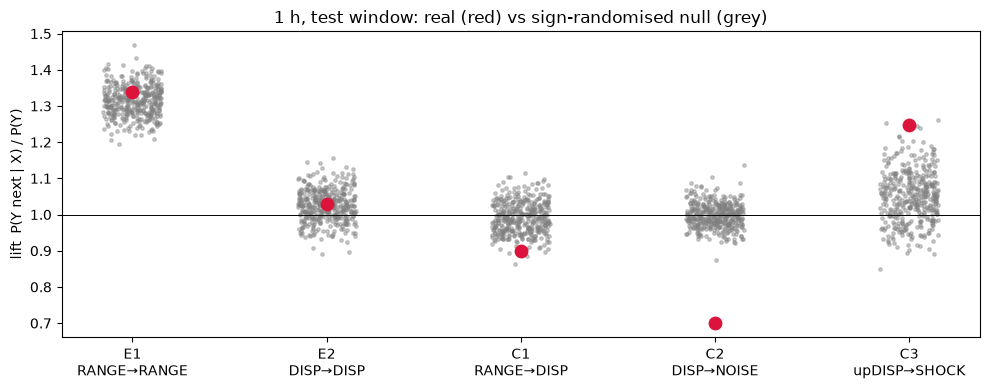

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
tests = [t for t, _, _ in rs.TESTS]
for k, t in enumerate(tests):
    NB = [r['null_counts'][N0] for r in RES.values()]; RB = [r['counts'][N0] for r in RES.values()]
    ln = np.array([rs.pooled_lift([nb[j] for nb in NB], ('test', t), null=True) for j in range(P.n_null)])
    ax.scatter(np.full(len(ln), k) + np.random.default_rng(k).uniform(-0.15, 0.15, len(ln)), ln, s=6, alpha=0.4, color='grey')
    ax.scatter([k], [rs.pooled_lift(RB, ('test', t))], s=80, color='crimson', zorder=3)
ax.axhline(1, color='black', lw=0.7)
ax.set_xticks(range(len(tests)), [f'{t}\n{x}→{y}' for t, x, y in rs.TESTS])
ax.set_ylabel('lift  P(Y next | X) / P(Y)'); ax.set_title('1 h, test window: real (red) vs sign-randomised null (grey)')
plt.tight_layout(); plt.show()

## 4. Save compact outputs

In [13]:
base.reset_index().to_csv(OUT / '01_label_base_rates.csv', index=False)
thr.to_csv(OUT / '01_thresholds.csv')
allres.to_csv(OUT / '01_results_all_scales.csv', index=False)
decision.to_csv(OUT / '01_decision.csv', index=False)
per_asset.to_csv(OUT / '01_per_asset.csv', index=False)
tm_real.to_csv(OUT / '01_transitions_real_test.csv'); tm_null.to_csv(OUT / '01_transitions_null_test.csv')
runs.to_csv(OUT / '01_run_lengths_test.csv')
shock_dir.to_csv(OUT / '01_shock_direction_test.csv', index=False)
manifest = {'registration': REG, 'assets_run': list(RES), 'synthetic': SYNTHETIC,
            'decision': decision.to_dict(orient='records'), 'run_utc': str(pd.Timestamp.now(tz='UTC'))}
(OUT / '01_manifest.json').write_text(json.dumps(manifest, indent=2, default=str), encoding='utf-8')
print('saved to', OUT, sorted(p.name for p in OUT.iterdir()))

saved to D:\Projects\deribit_market_data\notebooks\Regime_Structure\01 ['01_decision.csv', '01_label_base_rates.csv', '01_manifest.json', '01_per_asset.csv', '01_primary.csv', '01_results_all_scales.csv', '01_run_lengths_test.csv', '01_shock_direction_test.csv', '01_thresholds.csv', '01_transitions_null_test.csv', '01_transitions_real_test.csv']
